# 04. Decision Tree Classifier

**Project** · Bank Loan Approval  
**Problem type** · Classification

This dataset is synthetic and designed for education. Keep its predictions within the exercise. Any real-world financial, medical, safety, educational or employment decision requires independent evidence and validation.

Start with Sections 1–9 for your first model. Then try parameter tuning and the interview exercises. Run the code cells in order because each step uses results from earlier cells.

## 1. Introduction

A decision tree classifies with a sequence of questions such as whether debt-to-income is below a threshold. Each decision node routes a row to a child and each leaf gives class frequencies. It can represent rules that use one feature only after another feature crosses a threshold.

By the end, you can implement the pipeline, explain how it predicts and use holdout results to identify where it struggles.

## 2. Understand the Dataset

The log-odds score includes credit thresholds at 620 and 665, debt ratios around 0.37–0.50, an amount-to-income ratio below six, years employed and a penalty when low credit and elevated debt coincide. A Bernoulli draw adds label uncertainty. These rules are educational and do not represent lending policy.

| Column | Type | Units or values | Meaning |
| --- | --- | --- | --- |
| `credit_score` | integer | score points | Synthetic credit score |
| `monthly_income_usd` | integer | USD/month | Gross monthly income |
| `loan_amount_usd` | integer | USD | Principal requested |
| `debt_to_income_ratio` | decimal | fraction | Monthly debt payments divided by monthly income |
| `employment_years` | integer | years | Years of employment |
| `loan_status` | string | Rejected, Approved | Observed class label |

**Independent variables (X)** · `credit_score`, `monthly_income_usd`, `loan_amount_usd`, `debt_to_income_ratio`, `employment_years`.

**Dependent variable (y)** · `loan_status` is the class to predict. The preview shows the first 10 rows, dimensions and stored types. Blank features, where present, are intentional.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

csv_name = "04_loan_approval.csv"
csv_path = Path("../datasets") / csv_name

# Also look in the project folder or the location used for Colab uploads.
if not csv_path.is_file():
    csv_path = Path("datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path("Machine_Learning_Complete_Guide/datasets") / csv_name
if not csv_path.is_file():
    csv_path = Path(csv_name)

df = pd.read_csv(csv_path, keep_default_na=False, na_values=[""])
print("Dataset shape:", df.shape)
display(df.head(10))
display(df.dtypes)

Dataset shape: (1500, 6)


,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years,loan_status
0,813,3087,16477,0.661,7,Approved
1,763,11255,44544,0.237,11,Approved
2,822,3612,4224,0.341,2,Approved
3,840,13152,12136,0.294,1,Approved
4,523,4077,47277,0.448,23,Rejected
5,744,5560,35016,0.110,15,Approved
6,639,9007,47489,0.171,25,Approved
7,481,7525,54876,0.275,6,Rejected
8,687,4424,10579,0.159,10,Approved
9,559,7529,11222,0.464,19,Rejected


credit_score              int64
monthly_income_usd        int64
loan_amount_usd           int64
debt_to_income_ratio    float64
employment_years          int64
loan_status                 str
dtype: object

## 3. Mathematical Understanding

For class fractions $p_k$ at a node, Gini impurity is $G=1-\sum_k p_k^2$ and entropy is $H=-\sum_k p_k\log_2(p_k)$, with $0\log_2(0)$ treated as zero. Here $k$ indexes classes. The split gain for impurity measure $I$ is $I_P-(n_L/n_P)I_L-(n_R/n_P)I_R$. Subscripts $P,L,R$ denote the parent, left child and right child, and $n$ denotes row counts.

A node with four approvals and four rejections has Gini $0.50$ and entropy $1$ bit. Splitting into children of size four with approval counts three and one yields Gini $0.375$ in both children and Gini gain $0.125$. A row that reaches the three-approval leaf receives an approval probability of $3/4$ in this unweighted example.

[scikit-learn user guide](https://scikit-learn.org/stable/modules/tree.html)

## 4. Working Principle

Try many feature cutoffs at the root. Keep the cutoff with the largest weighted impurity reduction. Repeat separately for each child until stopping limits apply. Route a new applicant through the resulting questions and read the most frequent class in the leaf.

| Node | Class counts | Gini |
| --- | --- | --- |
| Before split | 4 Approved, 4 Rejected | 0.500 |
| Left leaf | 3 Approved, 1 Rejected | 0.375 |
| Right leaf | 1 Approved, 3 Rejected | 0.375 |

**Workflow diagram**

`Raw input` → `Imputed numeric values and any category indicators` → `Recursively splits to create purer leaves` → `Class prediction`.

## 5. Dataset Exploration

The first and last rows verify parsing. Shape and info reveal size, stored types and non-missing counts. Summary statistics show typical values, ranges and spread. Missingness and duplicate counts identify possible cleanup needs. The target plot shows class balance. Feature plots show variation. Pearson correlation measures linear association. The category target is excluded. The features and evaluation design are fixed before modeling.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
TARGET = "loan_status"
FEATURES = ["credit_score","monthly_income_usd","loan_amount_usd","debt_to_income_ratio","employment_years"]
NUMERIC = ["credit_score","monthly_income_usd","loan_amount_usd","debt_to_income_ratio","employment_years"]
CATEGORICAL = []
SEED = 42
LABELS = ["Rejected","Approved"]

In [3]:
df.info()
display(df.head())
display(df.tail())
display(df.describe(include="all").T)
display(pd.DataFrame({"Missing": df.isna().sum(), "Missing %": 100 * df.isna().mean()}).round(1))
print("Exact duplicate rows:", df.duplicated().sum())
print("Repeated feature rows:", df.duplicated(subset=FEATURES).sum())

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   credit_score          1500 non-null   int64  
 1   monthly_income_usd    1500 non-null   int64  
 2   loan_amount_usd       1500 non-null   int64  
 3   debt_to_income_ratio  1470 non-null   float64
 4   employment_years      1500 non-null   int64  
 5   loan_status           1500 non-null   str    
dtypes: float64(1), int64(4), str(1)
memory usage: 82.2 KB


,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years,loan_status
0,813,3087,16477,0.661,7,Approved
1,763,11255,44544,0.237,11,Approved
2,822,3612,4224,0.341,2,Approved
3,840,13152,12136,0.294,1,Approved
4,523,4077,47277,0.448,23,Rejected


,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years,loan_status
1495,651,5653,48854,0.404,0,Rejected
1496,600,6035,39820,0.345,4,Approved
1497,487,1807,20706,0.187,5,Approved
1498,800,9506,40030,0.170,11,Approved
1499,794,10966,21596,0.218,9,Approved


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
credit_score,1500.0,NaN,NaN,NaN,666.173333,107.054857,480.0,572.0,665.0,763.0,850.0
monthly_income_usd,1500.0,NaN,NaN,NaN,8177.886,3618.560254,1804.0,5014.75,8143.5,11256.75,14486.0
loan_amount_usd,1500.0,NaN,NaN,NaN,29597.358667,16253.22381,2010.0,15455.75,28839.0,43783.0,57960.0
debt_to_income_ratio,1470.0,NaN,NaN,NaN,0.377059,0.186098,0.05,0.21325,0.3815,0.537,0.699
employment_years,1500.0,NaN,NaN,NaN,12.458667,7.564552,0.0,6.0,12.0,19.0,25.0
loan_status,1500,2,Approved,1021,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Missing,Missing %
credit_score,0,0.0
monthly_income_usd,0,0.0
loan_amount_usd,0,0.0
debt_to_income_ratio,30,2.0
employment_years,0,0.0
loan_status,0,0.0


Exact duplicate rows: 0
Repeated feature rows: 0


### Plot the target

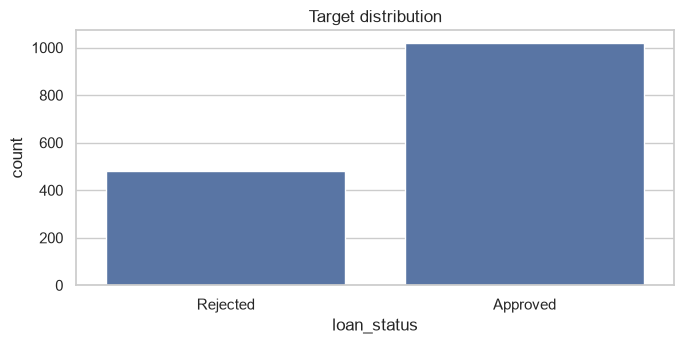

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.countplot(data=df, x=TARGET, order=LABELS, ax=ax)
ax.set_title("Target distribution")
fig.tight_layout()
plt.show()

### Look at the input features

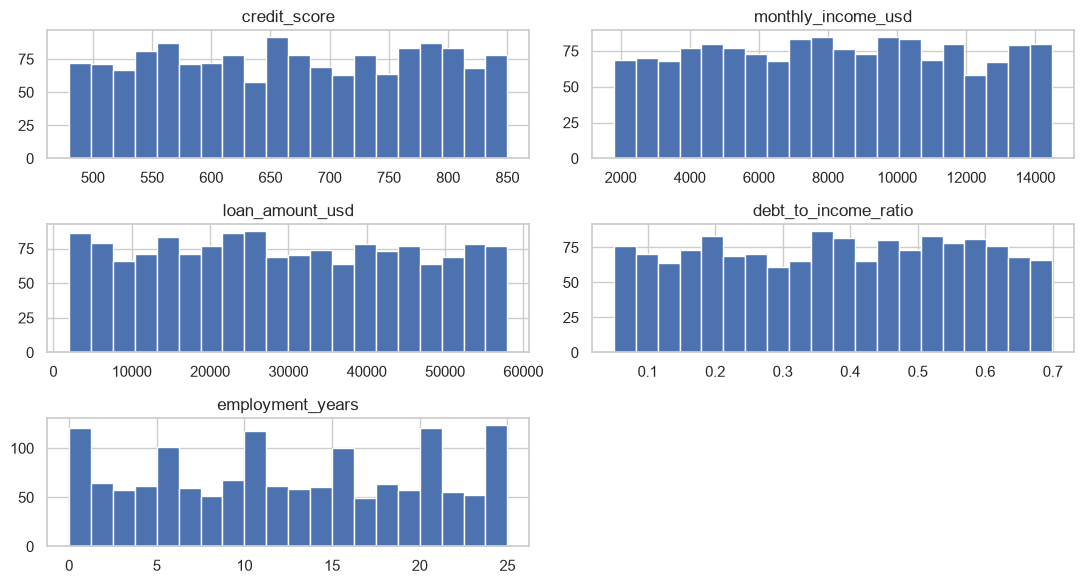

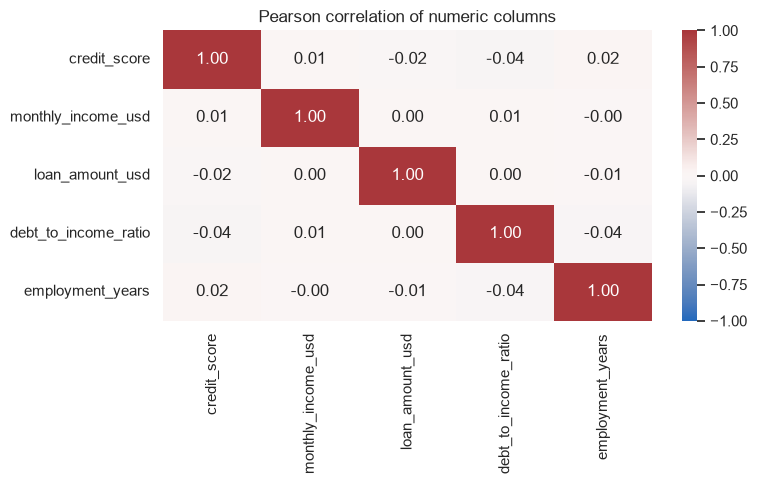

In [5]:
df[NUMERIC].hist(figsize=(11, 6), bins=20)
plt.tight_layout()
plt.show()

correlation_columns = NUMERIC
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(df[correlation_columns].corr(), annot=True, fmt=".2f", cmap="vlag",
            center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Pearson correlation of numeric columns")
fig.tight_layout()
plt.show()

## 6. Data Preprocessing

Select the input columns and target explicitly. Stratification preserves approximate class proportions. The numeric branch fills blanks using training medians. This dataset has no categorical predictors. Tree splits use the ordering of values, so scaling is unnecessary. The pipeline fits each preprocessing step after the split and repeats it in each training fold.

Exact and feature-only duplicate counts are listed above. Identical measurements with distinct outcomes can represent legitimate observations.

### 1. Choose the inputs and target

In [6]:
# X contains the inputs. y contains the answer for each row.
X = df[FEATURES]
label_codes = {'Rejected': 0, 'Approved': 1}
y = df[TARGET].map(label_codes)

### 2. Split the rows into training and test sets

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))

Training rows: 1200
Test rows: 300


### 3. Prepare the columns

The next cell sets up the cleaning steps. They learn their values later, when you fit the model.

In [8]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

# Fill blank numbers with the training median.
numeric_preprocess = SimpleImputer(strategy="median")

preprocess = ColumnTransformer(
    [
        ("numeric", numeric_preprocess, NUMERIC),
    ],
    verbose_feature_names_out=False,
)

## 7. Model Implementation

`max_depth` limits the number of levels below the root. `min_samples_leaf` prevents small terminal groups. `min_samples_split` puts a floor on how many rows a node needs to attempt a split. `criterion` chooses Gini or entropy in the search.

- The estimator import provides the algorithm implementation.
- `Pipeline` joins preprocessing and the model in execution order.
- `fit(X_train, y_train)` learns transformations and parameters from training rows.
- `predict(...)` applies the fitted steps to new rows. The first holdout row gives a preview before scoring the entire split.

### Create the model

In [9]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

estimator = DecisionTreeClassifier(max_depth=4, min_samples_leaf=20, criterion="gini", random_state=SEED)
model = Pipeline([
    ("preprocess", preprocess),
    ("model", estimator),
])

### Fit on the training rows

In [10]:
# Learn from the training rows.
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['credit_score','monthly_income_usd','loan_amount_usd', 'debt_to_income_ratio','employment_years']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent 

### Predict on the test rows

In [11]:
# Predict using the held-out inputs.
predictions = model.predict(X_test)
display(X_test.head(1))
print("Example predicted class:", LABELS[predictions[0]])

,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years
731,779,7270,55276,0.564,22


Example predicted class: Approved


## 8. Model Evaluation

Let $TP$ count correctly predicted positives, $TN$ correctly predicted negatives, $FP$ false positives, $FN$ false negatives and $N$ all test rows. Higher values indicate better scores, subject to the baseline and the costs of different errors.

| Measure | Formula and interpretation |
| --- | --- |
| Accuracy | $(TP+TN)/N$ for binary outcomes, or the proportion of correct predictions for multiple classes. |
| Precision | $TP/(TP+FP)$. Of the predicted positives, how many really were positive? |
| Recall | $TP/(TP+FN)$. Of the actual positives, how many did the model catch? |
| F1 | $2PR/(P+R)$ for precision $P$ and recall $R$. It is their harmonic mean. |
| ROC-AUC | Area $\int_0^1 \mathrm{TPR}\,d(\mathrm{FPR})$, with $\mathrm{TPR}=TP/(TP+FN)$ and $\mathrm{FPR}=FP/(FP+TN)$. Binary AUC measures the chance of ranking a random positive above a random negative, counting ties as half. Around 0.5 corresponds to chance ranking. |
| Confusion matrix | Entry $(i,j)$ counts rows with actual class $i$ and predicted class $j$. A strong diagonal indicates correct classifications. Examine the off-diagonal cells for costly errors. |
| Classification report | Applies precision, recall and F1 per class. Support counts actual examples per class. Macro averaging weights classes equally, and weighted averaging uses support. |

The positive class is **Approved**. ROC-AUC ranks by its estimated probability. A prior-only classifier gives a baseline. A class with no positive predictions gets zero precision by convention.

In [12]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

AVERAGE = "binary"
CLASS_IDS = np.arange(len(LABELS))

test_scores = model.predict_proba(X_test)[:, 1]

initial_metrics = {
    "Accuracy": accuracy_score(y_test, predictions),
    "Precision": precision_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, test_scores),
}
display(pd.Series(initial_metrics, name="Test score").round(3))

Accuracy     0.863
Precision    0.865
Recall       0.946
F1           0.904
ROC-AUC      0.877
Name: Test score, dtype: float64

### Compare with a simple baseline

In [13]:
# A baseline knows the training class frequencies and sees no input features.
baseline = DummyClassifier(strategy="prior")
baseline_train = np.zeros((len(y_train), 1))
baseline_test = np.zeros((len(y_test), 1))
baseline.fit(baseline_train, y_train)

baseline_predictions = baseline.predict(baseline_test)
baseline_scores = baseline.predict_proba(baseline_test)[:, 1]

baseline_metrics = {
    "Accuracy": accuracy_score(y_test, baseline_predictions),
    "Precision": precision_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, baseline_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, baseline_scores),
}
display(pd.DataFrame([baseline_metrics, initial_metrics], index=["Baseline", "Model"]).round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.680,0.680,1.000,0.810,0.500
Model,0.863,0.865,0.946,0.904,0.877


### Read the results for each class

In [14]:
print(classification_report(
    y_test, predictions, labels=CLASS_IDS, target_names=LABELS, zero_division=0
))

              precision    recall  f1-score   support

    Rejected       0.86      0.69      0.76        96
    Approved       0.87      0.95      0.90       204

    accuracy                           0.86       300
   macro avg       0.86      0.82      0.83       300
weighted avg       0.86      0.86      0.86       300



## 9. Visualizations

Read the confusion matrix by row for each actual class. Off-diagonal cells show the direction and size of confusions. The ROC curve shows the recall and false-positive trade-off across score thresholds.

Read a tree from top to bottom. The left branch satisfies the displayed condition. The plot shows the first three decision levels. The node numbers show the path taken by the first test row.

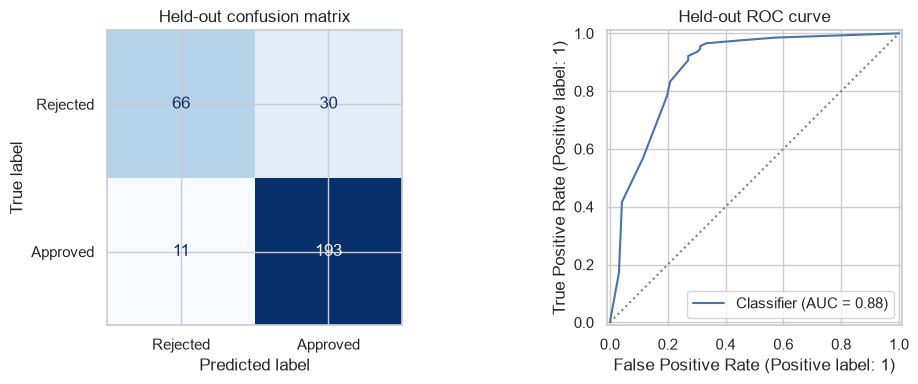

In [15]:
fig, (ax, roc_ax) = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, labels=CLASS_IDS, display_labels=LABELS,
                                        colorbar=False, cmap="Blues", ax=ax)
ax.set_title("Held-out confusion matrix")
RocCurveDisplay.from_predictions(y_test, test_scores, pos_label=1, ax=roc_ax)
roc_ax.plot([0, 1], [0, 1], linestyle=":", color="grey")
roc_ax.set_title("Held-out ROC curve")
fig.tight_layout()
plt.show()

### A closer look at this model

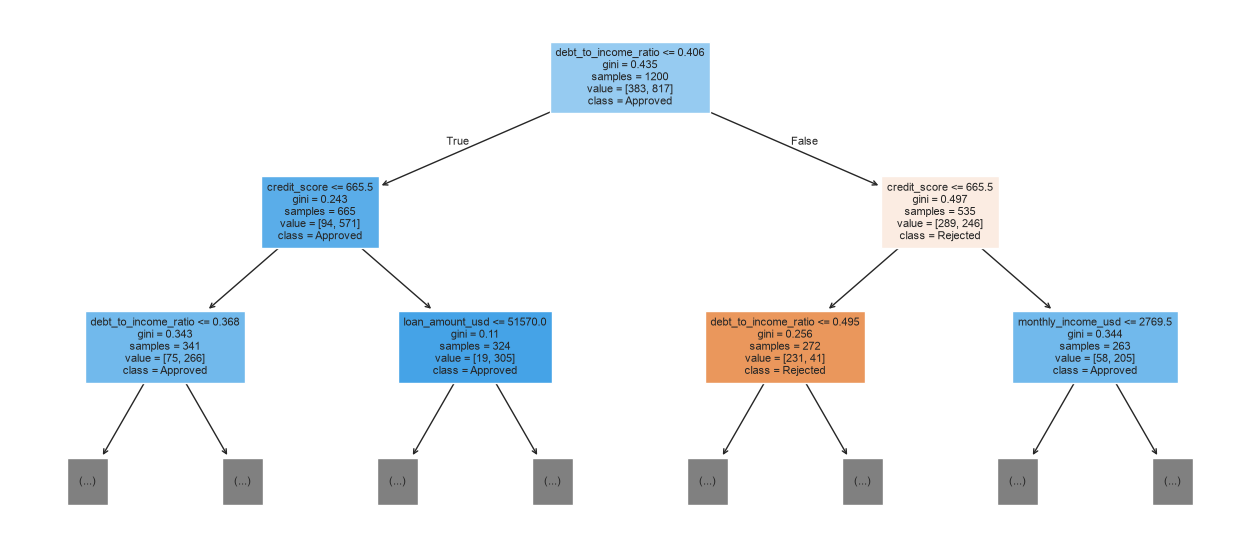

Visited nodes: [ 0 14 22 24 25]
Final leaf: 25


In [16]:
tree = model.named_steps["model"]
feature_names = model.named_steps["preprocess"].get_feature_names_out()
plt.figure(figsize=(16, 7))
plot_tree(tree, feature_names=feature_names, class_names=LABELS, filled=True, max_depth=2, fontsize=8)
plt.show()

row = model.named_steps["preprocess"].transform(X_test.head(1))
visited_nodes = tree.decision_path(row).indices
print("Visited nodes:", visited_nodes)
print("Final leaf:", visited_nodes[-1])

## 10. Hyperparameter Tuning

GridSearchCV tries the grid with three shuffled stratified folds within the training data. Each candidate gets a freshly fitted pipeline per fold. Rank by positive-class F1. `refit=True` fits the winner on all training rows. Use the CV ranks to choose parameters and the holdout to report performance.

`max_depth` limits the number of levels below the root. `min_samples_leaf` prevents small terminal groups. `min_samples_split` puts a floor on how many rows a node needs to attempt a split. `criterion` chooses Gini or entropy in the search.

[GridSearchCV documentation](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)

### Set up the candidate settings

In [17]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

param_grid = {"model__max_depth": [3, 5, None], "model__min_samples_split": [20, 60], "model__criterion": ["gini", "entropy"]}
validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
search = GridSearchCV(model, param_grid, scoring="f1", cv=validation,
                      refit=True, n_jobs=1, error_score="raise")

### Search using training rows

In [18]:
search.fit(X_train, y_train)
tuned_model = search.best_estimator_
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results["Mean CV F1"] = results["mean_test_score"]
print("Best training-CV parameters:", search.best_params_)
display(results[["rank_test_score", "Mean CV F1", "std_test_score", "params"]].head().round(3))

Best training-CV parameters: {'model__criterion': 'entropy', 'model__max_depth': 5, 'model__min_samples_split': 60}


,rank_test_score,Mean CV F1,std_test_score,params
11,1,0.879,0.013,"{'model__criterion': 'entropy', 'model__max_de..."
9,1,0.879,0.013,"{'model__criterion': 'entropy', 'model__max_de..."
6,3,0.878,0.016,"{'model__criterion': 'entropy', 'model__max_de..."
7,3,0.878,0.016,"{'model__criterion': 'entropy', 'model__max_de..."
0,5,0.872,0.007,"{'model__criterion': 'gini', 'model__max_depth..."


### Compare the models on the test set

In [19]:
tuned_predictions = tuned_model.predict(X_test)
tuned_scores = tuned_model.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "Accuracy": accuracy_score(y_test, tuned_predictions),
    "Precision": precision_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "Recall": recall_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "F1": f1_score(y_test, tuned_predictions, average=AVERAGE, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, tuned_scores),
}
comparison = pd.DataFrame(
    [baseline_metrics, initial_metrics, tuned_metrics],
    index=["Baseline", "First model", "Tuned model"],
)
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Baseline,0.680,0.680,1.000,0.810,0.500
First model,0.863,0.865,0.946,0.904,0.877
Tuned model,0.863,0.859,0.956,0.905,0.866


## 11. Real-World Prediction

Pass three new examples to the CV-selected pipeline. The result shows the estimated probability of each class. Read those estimates in the context of the synthetic population.

### Enter three new examples

In [20]:
examples = pd.DataFrame([
    [735, 6800, 22000, 0.22, 8],
    [590, 3800, 31000, 0.54, 1],
    [665, 5400, 32000, 0.36, 4],
], columns=FEATURES)
display(examples)

,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years
0,735,6800,22000,0.22,8
1,590,3800,31000,0.54,1
2,665,5400,32000,0.36,4


### Make predictions

In [21]:
sample_inputs = examples
prediction_model = tuned_model
sample_predictions = prediction_model.predict(sample_inputs)
example_output = examples.copy()
example_output["Scenario"] = ["Higher credit and lower debt ratio","Lower credit and higher debt ratio","Near the generator’s credit and debt cutoffs"]
probabilities = prediction_model.predict_proba(sample_inputs)
example_output["Predicted class"] = np.take(LABELS, sample_predictions)

# Each row contains the class probabilities for one new example.
probability_table = pd.DataFrame(probabilities.round(3), columns=LABELS)
probability_table = probability_table.add_prefix("P(").add_suffix(")")
example_output = pd.concat([example_output, probability_table], axis=1)
display(example_output)

,credit_score,monthly_income_usd,loan_amount_usd,debt_to_income_ratio,employment_years,Scenario,Predicted class,P(Rejected),P(Approved)
0,735,6800,22000,0.22,8,Higher credit and lower debt ratio,Approved,0.036,0.964
1,590,3800,31000,0.54,1,Lower credit and higher debt ratio,Rejected,1.000,0.000
2,665,5400,32000,0.36,4,Near the generator’s credit and debt cutoffs,Approved,0.036,0.964


## 12. Limitations and Advantages

Shallow trees expose the decision path and capture interactions. Greedy axis-aligned splits can miss smooth diagonal boundaries and change when data changes. A tiny leaf produces unreliable class frequencies. A restrictive depth can underfit and unbounded growth can overfit. Use a tree for a small rules-based demonstration or inspectable baseline. Use a larger ensemble if prediction stability dominates interpretability.

## 13. Interview Preparation

### A. 30-second explanation

> I built a shallow decision tree that classifies a synthetic loan outcome. The tree recursively chooses cutoffs that reduce weighted class impurity, then predicts from the leaf’s class counts. I evaluated approvals and rejections separately and inspected a tree plot to explain its decisions.

### B. 90-second technical explanation

> I built a shallow decision tree that classifies a synthetic loan outcome. The tree recursively chooses cutoffs that reduce weighted class impurity, then predicts from the leaf’s class counts. I evaluated approvals and rejections separately and inspected a tree plot to explain its decisions. My target was loan status, and the inputs were credit score, monthly income usd, loan amount usd, debt to income ratio, employment years. Try many feature cutoffs at the root. Keep the cutoff with the largest weighted impurity reduction. Repeat separately for each child until stopping limits apply. Route a new applicant through the resulting questions and read the most frequent class in the leaf. I held out 20% of the rows and fitted preprocessing within each training fold. I compared F1 and ROC-AUC with a prior baseline and read the confusion matrix to identify the classes that were easiest to confuse. The inputs and labels were generated for teaching, so the holdout performance describes this exercise. For real data I would confirm which inputs are available at prediction time and build a split that reflects where the model will be used.

### C. Ten technical questions

1. **What is a decision node?** An internal node that applies a feature threshold.
2. **What is a leaf?** A terminal node storing class counts or weighted frequencies.
3. **What impurity has a pure node?** Both Gini and entropy are zero.
4. **Why weight child impurities?** An improvement for a tiny group should count less than an improvement for many rows.
5. **Why call the search greedy?** It selects the best current split without optimizing all future branches jointly.
6. **What controls leaf size?** min_samples_leaf.
7. **Can the tree learn interactions?** Yes. A feature can split only within an earlier branch.
8. **Do numerical features require scaling?** No. Split ordering is preserved by a strictly increasing transformation.
9. **What is pruning?** Removing weak branches to reduce model complexity, for example with cost complexity pruning.
10. **How are probabilities formed?** As class fractions in the reached leaf, weighted if sample weights are used.

### D. Five scenario questions

1. **Training accuracy is high but test accuracy drops. What change would you try?** Limit depth, increase leaf size, or tune pruning using training folds.
2. **A threshold changes across folds. What would you report?** Show sensitivity of the rule and treat the split as an unstable model estimate.
3. **The data includes eventual repayment outcome. Use it for approval prediction?** Exclude it because it is unavailable at application time.
4. **Most examples are approved. Is accuracy sufficient?** Compare with a majority baseline and inspect class-specific recall.
5. **A domain expert wants a reason for one output. How can you help?** Trace the row through its decision path and report the leaf’s class mix.

### E. Three common mistakes

- Reading impurity as a misclassification percentage. Check its formula.
- Allowing single-row probability leaves. Tune minimum leaf size.
- Using the tree path as proof of an actual lending rule. Describe it as a rule learned from synthetic labels.

### F. Complete project explanation

Use the measured scores in a short project walkthrough. Start with the problem, explain the pipeline and close with what the evaluation can support. This cell inserts results from the current run.

In [22]:
from IPython.display import Markdown

summary = (
    "I built a supervised classification project for bank loan approval using Decision Tree Classifier. I generated 1,500 synthetic observations and used credit score, monthly income usd, loan amount usd, debt to income ratio, employment years to predict loan status. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. "
    f"On the holdout, the CV-selected model reached {tuned_metrics['F1']:.3f} F1 for Approved, versus "
    f"{baseline_metrics['F1']:.3f} for the baseline, with ROC-AUC {tuned_metrics['ROC-AUC']:.3f}. "
    "I traced one applicant from the root to its leaf and explained the qualifying thresholds. These results apply to the synthetic data and should be validated on representative observations before practical use."
)
display(Markdown("> " + summary))

> I built a supervised classification project for bank loan approval using Decision Tree Classifier. I generated 1,500 synthetic observations and used credit score, monthly income usd, loan amount usd, debt to income ratio, employment years to predict loan status. I used a holdout and a preprocessing pipeline fitted within training folds. I compared the selected estimator with a simple baseline. On the holdout, the CV-selected model reached 0.905 F1 for Approved, versus 0.810 for the baseline, with ROC-AUC 0.866. I traced one applicant from the root to its leaf and explained the qualifying thresholds. These results apply to the synthetic data and should be validated on representative observations before practical use.